## 1. Подготовка датасета

Хотелось поработать с ecom или retail данными. Что хотелось:

- Не синтетику
- Чтоб было достаточно данных о пользователях и о товарах
- Чтобы была информация о разных взаимодействиях
- Чтоб датасет подходил по критериям задания по размеру

Нашел соревнование H&M с хорошим датасетом

https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations

Датасет открытый, но нужно принять участие в соревновании, чтобы получить прямой доступ к данным. Я работал в ui кагла и датасет подключал в input, поэтому он у меня уже доступен. Рекомендую сделать также, но если не хотите работать из кагла.

Альтернативный вариант: скачать articles.csv, customers.csv и transactions_train.csv со страницы соревнования после принятия его правил и поместите их в папку data рядом с ноутбуком. После этого замените строку-аргумент Path на "data". Утверждается, что работает на Python 3.12 притом, что все зависимости из requirements.txt установлены

In [4]:
from pathlib import Path


DATASET_PATH = Path("/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations")

Если не было входа в kaggle в текущем окружении, то по идее код в комментах откроет тебе браузер и предоставит возможность войти в аккаунт

In [5]:
import pandas as pd


articles = pd.read_csv(DATASET_PATH / "articles.csv")
customers = pd.read_csv(DATASET_PATH / "customers.csv")
transactions_train = pd.read_csv(DATASET_PATH / "transactions_train.csv")

transactions_train

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2
...,...,...,...,...,...
31788319,2020-09-22,fff2282977442e327b45d8c89afde25617d00124d0f999...,929511001,0.059305,2
31788320,2020-09-22,fff2282977442e327b45d8c89afde25617d00124d0f999...,891322004,0.042356,2
31788321,2020-09-22,fff380805474b287b05cb2a7507b9a013482f7dd0bce0e...,918325001,0.043203,1
31788322,2020-09-22,fff4d3a8b1f3b60af93e78c30a7cb4cf75edaf2590d3e5...,833459002,0.006763,1


Имеется три таблицы (а еще папка с картинками и пример отправки решения в соревнования - нас не интересует)

- transactions_train - взаимодействия
- customers - пользователи (покупатели)
- articles - айтемы (товары)

Будем учиться рекомендовать товары покупателям. Релевантные - те, что купили

In [6]:
len(transactions_train), len(articles), len(customers)

(31788324, 105542, 1371980)

Очень большой исходный объем

In [7]:
transactions_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31788324 entries, 0 to 31788323
Data columns (total 5 columns):
 #   Column            Dtype  
---  ------            -----  
 0   t_dat             object 
 1   customer_id       object 
 2   article_id        int64  
 3   price             float64
 4   sales_channel_id  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.2+ GB


Надо по-нормальному импортировать типы везде

In [8]:
articles = pd.read_csv(
    DATASET_PATH / "articles.csv",
    dtype={
        "article_id": "int32",  # ID артикула
        "product_code": "int32",  # ID базового продукта
        "prod_name": "string",  # название товара
        "product_type_no": "int16",  # код типа товара
        "product_type_name": "category",  # тип товара
        "product_group_name": "category",  # общая группа товаров
        "graphical_appearance_no": "int16",  # код рисунка ткани
        "graphical_appearance_name": "category",  # рисунок ткани
        "colour_group_code": "int16",  # код цвета
        "colour_group_name": "category",  # цвет товара
        "perceived_colour_value_id": "int8",  # код светлоты цвета
        "perceived_colour_value_name": "category",  # светлота цвета
        "perceived_colour_master_id": "int8",  # код основного цвета
        "perceived_colour_master_name": "category",  # основной воспринимаемый цвет
        "department_no": "int16",  # код подразделения каталога
        "department_name": "category",  # подразделение каталога
        "index_code": "category",  # код раздела ассортимента
        "index_name": "category",  # раздел ассортимента
        "index_group_no": "int8",  # код крупной группы разделов
        "index_group_name": "category",  # крупная группа разделов
        "section_no": "int16",  # код секции каталога
        "section_name": "category",  # секция каталога
        "garment_group_no": "int16",  # код группы одежды
        "garment_group_name": "category",  # группа одежды
        "detail_desc": "string",  # текстовое описание товара
    },
)

customers = pd.read_csv(
    DATASET_PATH / "customers.csv",
    dtype={
        "customer_id": "string",  # ID покупателя
        "FN": "float32",  # флаг Fashion News
        "Active": "float32",  # флаг активности
        "club_member_status": "category",  # статус участия в клубе
        "fashion_news_frequency": "category",  # частота модных рассылок
        "age": "float32",  # возраст
        "postal_code": "string",  # анонимизированный почтовый индекс
    },
)

transactions_train = pd.read_csv(
    DATASET_PATH / "transactions_train.csv",
    dtype={
        "customer_id": "string",  # ID покупателя
        "article_id": "int32",  # ID артикула
        "price": "float32",  # нормализованная цена покупки
        "sales_channel_id": "category",  # канал покупки: магазин или онлайн
    },
    parse_dates=["t_dat"],  # дата покупки
)

Очень много самого разного, в том числе и излишнего для нас

In [9]:
customers[["postal_code"]].nunique()

postal_code    352899
dtype: int64

In [10]:
articles = articles.drop(columns=[
    "product_code",  # полезно, но не для нас (в наши модели прикручивать не будем)
    "product_type_no",  # числовые коды категорий удаляем
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_value_name",
    "perceived_colour_master_id",
    "perceived_colour_master_name",
    "department_no",  # слишком большая товарная иерархия тоже не нужна нам
    "department_name",
    "index_code",
    "index_name",
    "index_group_no",
    "section_no",
    "garment_group_no",
    "detail_desc",  # обрабатывать текст не будем
])

customers = customers.drop(columns=["postal_code"])  # уникальных значений слишком много

transactions_train = transactions_train.drop(columns=["sales_channel_id"])  # не известно до факта покупки

In [11]:
transactions_train.describe()

,t_dat,article_id,price
count,31788324,3.178832e+07,3.178832e+07
mean,2019-09-15 17:27:46.894452992,6.962272e+08,2.782928e-02
min,2018-09-20 00:00:00,1.087750e+08,1.694915e-05
25%,2019-03-28 00:00:00,6.328030e+08,1.581356e-02
50%,2019-08-25 00:00:00,7.145820e+08,2.540678e-02
75%,2020-03-29 00:00:00,7.865240e+08,3.388136e-02
max,2020-09-22 00:00:00,9.562170e+08,5.915254e-01
std,NaN,1.334480e+08,1.833207e-02


Нам так много данных не нужно, поэтому ограничимся одним годом

In [12]:
transactions_2019 = transactions_train[("2019-01-01" <= transactions_train["t_dat"]) & (transactions_train["t_dat"] < "2020-01-01")].copy()
transactions_2019.nunique()

t_dat             365
customer_id    976801
article_id      70739
price            8943
dtype: int64

Не хочется избавляться от холодных пользователей. Отберем пользователей, суммарное количество транзакций за выбранный год которых перейдет заданный порог

In [13]:
SEED = 42
TARGET_TRAIN = 400_000
N_ITEMS = 20_000

train_2019 = transactions_2019[transactions_2019["t_dat"] < "2019-11-01"]

train_counts = train_2019["customer_id"].value_counts()
user_order = customers["customer_id"].sample(frac=1, random_state=SEED).reset_index(drop=True)
counts = user_order.map(train_counts).fillna(0)

counts.sum()

np.int64(14080582)

Пользователи перед отбором перемешиваются

In [14]:
n_users = int(counts.cumsum().searchsorted(TARGET_TRAIN) + 1)
selected_users = user_order.iloc[:n_users]

data = transactions_2019[transactions_2019["customer_id"].isin(selected_users)].copy()
data = data.sort_values("t_dat").reset_index(drop=True)

selected_users.count(), data["t_dat"].count()

(np.int64(39468), np.int64(465926))

Теперь возьмем самые популярные среди выбранных пользователей товары (на train). Это будет нашим каталогом, из которого мы будем рекомендовать (и обучаться будем тоже на такой подвыборке)

In [15]:
train_raw = data[data["t_dat"] < "2019-11-01"].copy()
val = data[data["t_dat"].between("2019-11-01", "2019-11-30")].copy()
test = data[data["t_dat"].between("2019-12-01", "2019-12-31")].copy()

catalog = train_raw.groupby("article_id")["customer_id"].nunique().nlargest(N_ITEMS).index

train_raw["article_id"].nunique()

38164

В val и test остаются товары извне каталога (в том числе те, которых в принципе не существовало или не было покупок). Они будут учитываться в формуле метрик, но не будут рекомендоваться. В том числе так как мы не знаем из датасета, когда был опубликован определенный товар

In [16]:
known_items = val["article_id"].isin(train_raw["article_id"])
catalog_items = val["article_id"].isin(catalog)

catalog_items.mean(), (known_items & ~catalog_items).mean(), (~known_items).mean()

(np.float64(0.6835087719298245),
 np.float64(0.15166666666666667),
 np.float64(0.16482456140350876))

Мы жертвуем непопулярными товарами, чтобы мочь обучаться в kaggle значительно быстрее. Их соизмеримо с теми, которые мы в принципе мочь рекомендовать не должны

In [17]:
train = train_raw[train_raw["article_id"].isin(catalog)].copy()

Отделим данные, которые нам понадобятся

In [18]:
data_customers = customers[customers["customer_id"].isin(selected_users)].copy()
data_articles = articles[articles["article_id"].isin(data["article_id"])].copy()
data_articles_catalog = articles[articles["article_id"].isin(catalog)].copy()

В далеком будущем нам хочется (уже после того как подобрали гиперпараметры по val) добавить val данные и обучиться полностью. Никакого data-leak нету. У нас нету сильной проблемы с нехваткой данных, но продукты имеют свойство появляться не сразу или становиться популярными сезонно, так что хочется подобраться ближе по времени к test для лучших (и более реальных - так бы делали в проде) результатов

In [19]:
train_val_raw = pd.concat([train_raw, val], ignore_index=True)

catalog_new = train_val_raw.groupby("article_id")["customer_id"].nunique().nlargest(N_ITEMS).index
train_new = train_val_raw[train_val_raw["article_id"].isin(catalog_new)].copy()

data_articles_catalog_new = articles[articles["article_id"].isin(catalog_new)].copy()
data_customers_new = data_customers.copy()

Итого, осмысленная подготовка датасета завершена. Вот что осталось:

In [20]:
(
    len(data_customers),
    len(data_articles_catalog),
    len(train),
    len(val),

    len(data_customers_new),
    len(data_articles_catalog_new),
    len(train_new),
    len(test),
)

(39468, 20000, 368197, 34200, 39468, 20000, 396470, 31699)

## 2. EDA

Исследуем пропуски

In [21]:
train.isna().sum()

t_dat          0
customer_id    0
article_id     0
price          0
dtype: int64

In [22]:
data_articles_catalog.isna().sum()

article_id                   0
prod_name                    0
product_type_name            0
product_group_name           0
graphical_appearance_name    0
colour_group_name            0
index_group_name             0
section_name                 0
garment_group_name           0
dtype: int64

Начало хорошее. Для этих сущностей будем надеяться, что в val и test тоже нету плохих строк, а в случае если такие будут (их должно быть немного), заполним пропуски медианами / наиболее популярными значениями

In [23]:
data_customers.isna().sum()

customer_id                   0
FN                        25856
Active                    26228
club_member_status          170
fashion_news_frequency      452
age                         456
dtype: int64

У пользователей много пропусков

In [24]:
data_customers["FN"].value_counts(dropna=False)

FN
NaN    25856
1.0    13612
Name: count, dtype: int64

In [25]:
data_customers["Active"].value_counts(dropna=False)

Active
NaN    26228
1.0    13240
Name: count, dtype: int64

Тут, видимо, пропуск семантически означает категорию. Так и будем считать (тем более не хочется терять половину данных); будет две категориии: 1 и 0

In [26]:
data_customers["club_member_status"].value_counts(dropna=False)

club_member_status
ACTIVE        36632
PRE-CREATE     2650
NaN             170
LEFT CLUB        16
Name: count, dtype: int64

Интересно, что много членов клуба

In [27]:
data_customers["age"].value_counts(dropna=False)

age
21.0    1917
23.0    1657
25.0    1608
24.0    1566
20.0    1565
        ... 
89.0       2
87.0       2
85.0       1
92.0       1
90.0       1
Name: count, Length: 76, dtype: int64

Значений NaN совсем немного; удалим NaN из train, а на val/test будем подставлять самое популярное значение для категориального club_member_status и медиану для числового age

In [28]:
data_customers["fashion_news_frequency"].value_counts(dropna=False)

fashion_news_frequency
NONE         25366
Regularly    13630
NaN            452
Monthly         20
Name: count, dtype: int64

А вот тут с точки зрения логики может быть осмысленно завести отдельную категорию - Unknown

Теперь к дубликатам

In [29]:
train.duplicated().sum()

np.int64(36286)

Скорее всего, дубликаты означают несколько покупок, поэтому не трогаем, но помним 

In [30]:
data_customers["customer_id"].duplicated().sum(), data_articles_catalog["article_id"].duplicated().sum()

(np.int64(0), np.int64(0))

Хорошо, дубликатов нету

In [31]:
user_activity = train.groupby("customer_id")["article_id"].agg(["count", "nunique"])
user_activity.describe(percentiles=[.01, .05, .25, .75, .95, .99])

,count,nunique
count,25331.000000,25331.000000
mean,14.535431,12.470688
std,19.691458,16.134141
min,1.000000,1.000000
1%,1.000000,1.000000
5%,1.000000,1.000000
25%,3.000000,3.000000
50%,8.000000,7.000000
75%,18.000000,16.000000
95%,51.000000,43.000000


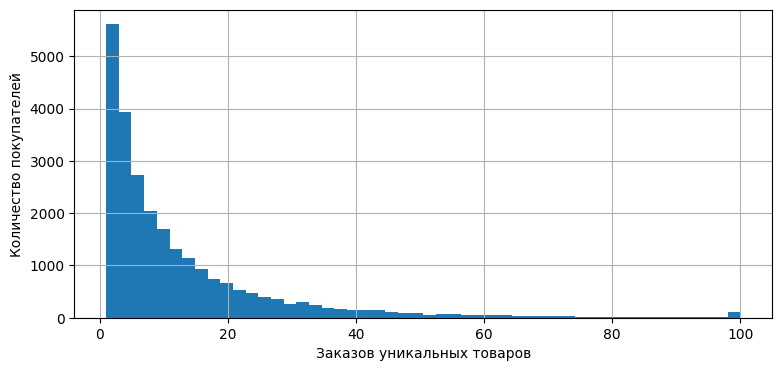

In [32]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(9, 4))
user_activity["nunique"].clip(upper=100).hist(bins=50, ax=ax)
ax.set(xlabel="Заказов уникальных товаров", ylabel="Количество покупателей")
plt.show()

In [28]:
len(selected_users), train["customer_id"].nunique()

(39468, 25331)

Около трети пользователей холодные. Из оставшихся как минимум четверть пользователей купили не больше 3 товаров. Холодных пользователей осталось в нашей подвыборке. Говоря о не холодных, обычно порядка 5-10 товаров как минимум люди брали. Для статистики по уникальным товарам примерно такие же цифры

In [29]:
item_popularity = train.groupby("article_id")["customer_id"].nunique()
item_popularity.describe(percentiles=[.01, .05, .25, .75, .95, .99])

count    20000.000000
mean        15.794750
std         19.856541
min          3.000000
1%           3.000000
5%           3.000000
25%          5.000000
50%          9.000000
75%         18.000000
95%         50.000000
99%         97.000000
max        477.000000
Name: customer_id, dtype: float64

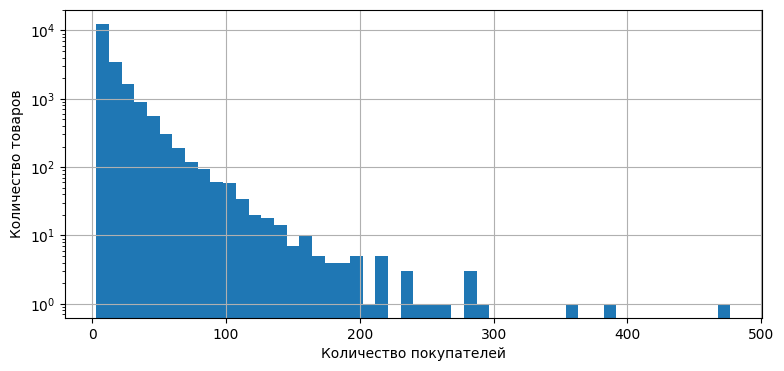

In [30]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(9, 4))
item_popularity.hist(bins=50, ax=ax, log=True)
ax.set(xlabel="Количество покупателей", ylabel="Количество товаров")
plt.show()

Среди товаров популярные объекты гораздо чаще. А совсем не скупленных товаров нету, так как мы отбирали самые популярные

In [31]:
cold_users = ~val["customer_id"].isin(train["customer_id"])
cold_items = ~val["article_id"].isin(train["article_id"])
in_catalog = val["article_id"].isin(catalog)

pd.Series({
    "Холодные пользователи": cold_users.mean(),
    "Холодные товары": cold_items.mean(),
    "Оба холодные": (cold_users & cold_items).mean(),
})

Холодные пользователи    0.123158
Холодные товары          0.316491
Оба холодные             0.037836
dtype: float64

Относительно val будет 12% холодных пользователей, 31% холодных товаров (больше, чем хотелось бы). Взаимодействий двух холодных объектов довольно мало

In [32]:
len(data_articles_catalog), train["article_id"].nunique()

(20000, 20000)

Тут мы уже понимаем, что у товаров, от которых мы отказались в каталоге, будем не больше чем по 3 покупки. Поведенческая информация была бы совсем шумной и не информативной, поэтому мы почти ничего не потеряли

In [33]:
n_users = len(selected_users)
n_items = len(catalog)
n_interactions = train[["customer_id", "article_id"]].drop_duplicates().shape[0]

n_users, n_items, n_interactions, n_interactions / n_users / n_items

(39468, 20000, 315895, 0.0004001912942130334)

Очень разреженная матрица

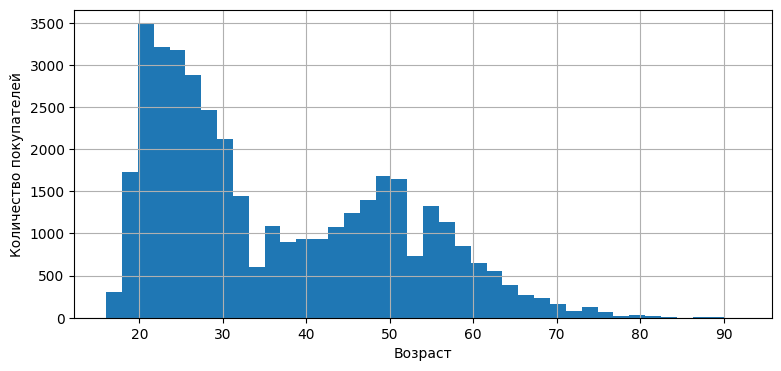

In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
data_customers["age"].hist(bins=40, ax=ax)
ax.set(xlabel="Возраст", ylabel="Количество покупателей")
plt.show()

Распределение похоже на сумму двух нормальных. Много молодежи и много возрастных пользователей

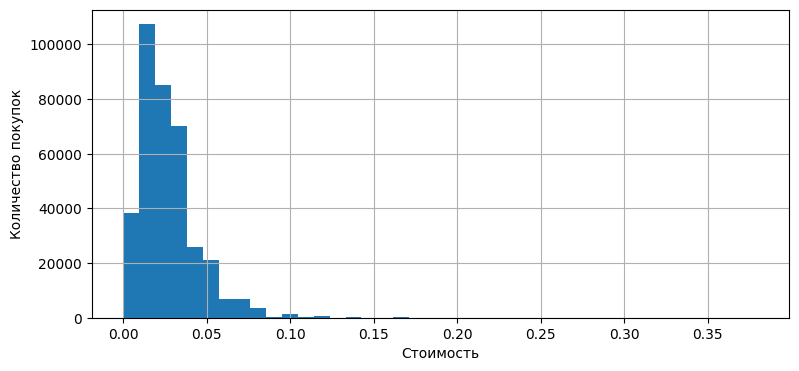

In [35]:
fig, ax = plt.subplots(figsize=(9, 4))
train["price"].hist(bins=40, ax=ax)
ax.set(xlabel="Стоимость", ylabel="Количество покупок")
plt.show()

Скорее всего, стоимость в условных единицах

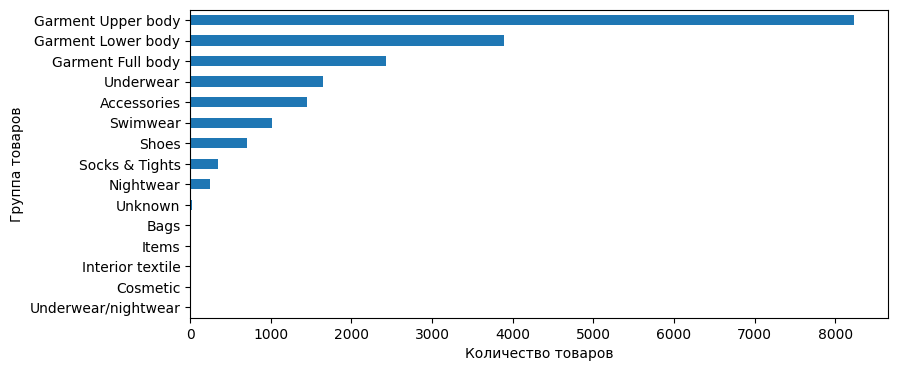

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
data_articles_catalog["product_group_name"].value_counts().head(15).sort_values().plot.barh(ax=ax)
ax.set(xlabel="Количество товаров", ylabel="Группа товаров")
plt.show()

Несколько категорий товаров лидируют с большим отрывом

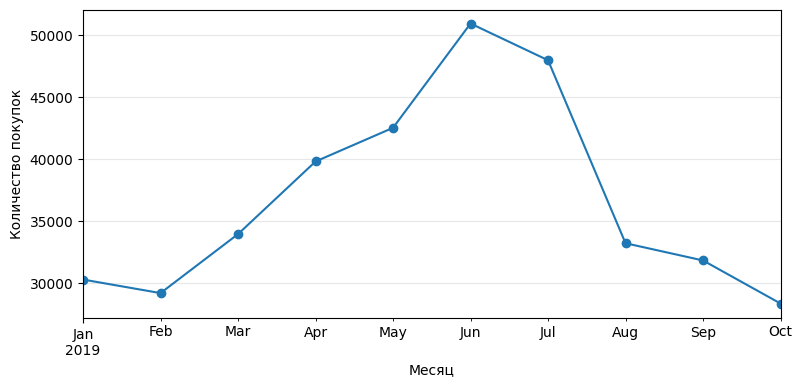

In [37]:
monthly_activity = train.groupby(data["t_dat"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(9, 4))
monthly_activity.plot(ax=ax, marker="o")
ax.set(xlabel="Месяц", ylabel="Количество покупок")
ax.grid(alpha=0.3)
plt.show()

Заметна сезонность - летом покупок гораздо больше

In [38]:
price_stats = train.groupby("article_id")["price"].agg(["count", "nunique", "min", "median", "max"])
price_stats["relative_range"] = (price_stats["max"] - price_stats["min"]) / price_stats["median"]

price_stats[["count", "nunique", "relative_range"]].describe(percentiles=[.25, .50, .75, .95, .99, .999])

,count,nunique,relative_range
count,20000.000000,20000.000000,20000.000000
mean,18.409850,5.796050,0.497134
std,24.359328,4.748777,0.489271
min,3.000000,1.000000,0.000000
25%,6.000000,3.000000,0.197959
50%,10.000000,4.000000,0.375731
75%,21.000000,7.000000,0.689398
95%,58.000000,15.000000,1.393200
99%,116.000000,23.000000,2.130387
99.9%,249.006000,39.001000,4.160926


Разброс цены есть и чаще всего существенный. Однако, кратные скачки редки, то есть почти всегда товар не меняет свою ценовую категорию. А еще (это наверно наиболе важно) формально в момент покупки товара стоимость уже была известна. В продакшене категория товара это вполне известное значение в момент рекомендации. В связи с этим предлагается использовать стоимость как категориальную фичу и проставлять категорию по медианной цене train данных

## 3. Подготовка выборок и протокол

Вспомним, какие у нас выборки собраны

In [39]:
originals = {
    "data_customers": data_customers.copy(),
    "data_articles_catalog": data_articles_catalog.copy(),
    "train": train.copy(),
    "val": val.copy(),
    
    "data_customers_new": data_customers_new.copy(),
    "data_articles_catalog_new": data_articles_catalog_new.copy(),
    "train_new": train_new.copy(),
    "test": test.copy(),
}

Проставим категорию стоимости. Мы сделали решение не рекомендовать товары вне каталога, а для всех их по определению была цена на train

In [40]:
def categorize_price(data, data_articles_catalog):
    price_median = data.groupby("article_id")["price"].median()
    price_category, _ = pd.qcut(price_median, q=5, labels=False, retbins=True, duplicates="drop")
    
    price_category = price_category.astype("int8")
    price_category.name = "price_category"
    
    processed = data_articles_catalog.merge(price_category, on="article_id", how="left")
    processed["price_category"] = processed["price_category"].astype("category")
    
    return processed


data_articles_catalog = categorize_price(train, data_articles_catalog)
data_articles_catalog_new = categorize_price(train_new, data_articles_catalog_new)

Удалим строки, которые решили удалить для обучения из обучающих выборок

In [41]:
valid_customers = data_customers.dropna(subset=["age", "club_member_status"])["customer_id"]

data_customers = data_customers[data_customers["customer_id"].isin(valid_customers)].copy()
train = train[train["customer_id"].isin(valid_customers)].copy()
train_new = train_new[train_new["customer_id"].isin(valid_customers)].copy()

Остальные оставшиеся пропуски мы хотим заполнять

In [42]:
data_customers["FN"] = data_customers["FN"].astype('category').cat.rename_categories({1.0: 1})
data_customers["Active"] = data_customers["Active"].astype('category').cat.rename_categories({1.0: 1})
data_customers

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
23,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,NaN,NaN,ACTIVE,NONE,35.0
31,00018385675844f7a6babbed41b5655b5727fb16483b6e...,1,1,ACTIVE,Regularly,68.0
76,00036ffb474cd9818bd0d9045fd5863b0167aabae75e61...,NaN,NaN,ACTIVE,NONE,28.0
78,000383021a8cf9a542b9c855b42f99aa76374873661e83...,NaN,NaN,ACTIVE,NONE,30.0
83,0003c98542d16e740156638a7d133d93360d3ff3d0b7ec...,1,1,ACTIVE,Regularly,22.0
...,...,...,...,...,...,...
1371737,fff4381593e170ca0aea188998487c830d9a4070c9ec4b...,NaN,NaN,ACTIVE,NONE,27.0
1371775,fff60c2d6ade407465a875a5640a1e6e2b5ed5f6ec21f5...,1,1,ACTIVE,Regularly,20.0
1371784,fff63d0371da299d55e8f71115eb6f9c484e05c9cc43ff...,1,1,ACTIVE,Regularly,28.0
1371792,fff6a015577ef67f79a6a9421091c2bff43d1772a548c6...,1,1,ACTIVE,Regularly,65.0


In [43]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


customer_pipeline = Pipeline([
    ("imputer", ColumnTransformer([
        ("flags", SimpleImputer(strategy="constant", fill_value=0), ["FN", "Active"]),
        ("age", SimpleImputer(strategy="median"), ["age"]),
        ("club", SimpleImputer(strategy="most_frequent"), ["club_member_status"]),
        ("news", SimpleImputer(strategy="constant", fill_value="Unknown"), ["fashion_news_frequency"]),
    ], verbose_feature_names_out=False).set_output(transform="pandas")),
])

article_pipeline = Pipeline([
    ("imputer", ColumnTransformer([
        ("name", SimpleImputer(strategy="constant", fill_value=""), ["prod_name"]),
        ("category", SimpleImputer(strategy="most_frequent"), data_articles_catalog.columns.drop(["article_id", "prod_name"]).tolist()),
    ], verbose_feature_names_out=False).set_output(transform="pandas")),
])

Чтобы не потерять ID после пайплайна давайте сложим их (ID) в индекс, а потом достанем обратно в столбец

In [44]:
customer_features = data_customers.columns.drop("customer_id")
article_features = data_articles_catalog.columns.drop("article_id")

data_customers_processed = customer_pipeline.fit_transform(data_customers.set_index("customer_id")[customer_features])
data_articles_catalog_processed = article_pipeline.fit_transform(data_articles_catalog.set_index("article_id")[article_features])

data_customers_processed = data_customers_processed.reset_index()
data_articles_catalog_processed = data_articles_catalog_processed.reset_index()

data_customers_processed.head()

,customer_id,FN,Active,age,club_member_status,fashion_news_frequency
0,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,0,0,35.0,ACTIVE,NONE
1,00018385675844f7a6babbed41b5655b5727fb16483b6e...,1,1,68.0,ACTIVE,Regularly
2,00036ffb474cd9818bd0d9045fd5863b0167aabae75e61...,0,0,28.0,ACTIVE,NONE
3,000383021a8cf9a542b9c855b42f99aa76374873661e83...,0,0,30.0,ACTIVE,NONE
4,0003c98542d16e740156638a7d133d93360d3ff3d0b7ec...,1,1,22.0,ACTIVE,Regularly


In [45]:
from sklearn.base import clone


customer_pipeline_new = clone(customer_pipeline)
article_pipeline_new = clone(article_pipeline)

data_customers_processed_new = customer_pipeline_new.fit_transform(data_customers_new.set_index("customer_id")[customer_features])
data_articles_catalog_processed_new = article_pipeline_new.fit_transform(data_articles_catalog_new.set_index("article_id")[article_features])

data_customers_processed_new = data_customers_processed_new.reset_index()
data_articles_catalog_processed_new = data_articles_catalog_processed_new.reset_index()

data_articles_catalog_processed_new.head()

,article_id,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,index_group_name,section_name,garment_group_name,price_category
0,108775015,Strap top,Vest top,Garment Upper body,Solid,Black,Ladieswear,Womens Everyday Basics,Jersey Basic,0
1,108775044,Strap top,Vest top,Garment Upper body,Solid,White,Ladieswear,Womens Everyday Basics,Jersey Basic,0
2,110065001,OP T-shirt (Idro),Bra,Underwear,Solid,Black,Ladieswear,Womens Lingerie,"Under-, Nightwear",2
3,110065002,OP T-shirt (Idro),Bra,Underwear,Solid,White,Ladieswear,Womens Lingerie,"Under-, Nightwear",1
4,110065011,OP T-shirt (Idro),Bra,Underwear,Solid,Light Beige,Ladieswear,Womens Lingerie,"Under-, Nightwear",1


В будущем будет приятнее работать, если привести ID покупателей и товаров к числовым индексам

In [46]:
from sklearn.preprocessing import OrdinalEncoder
import numpy as np


user_id_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int32))
])

item_id_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int32))
])

user_id_pipeline.fit(data_customers_processed[["customer_id"]])
item_id_pipeline.fit(data_articles_catalog_processed[["article_id"]])

train["user_id"] = user_id_pipeline.transform(train[["customer_id"]]).ravel()
train["item_id"] = item_id_pipeline.transform(train[["article_id"]]).ravel()

data_customers_processed["user_id"] = user_id_pipeline.transform(data_customers_processed[["customer_id"]]).ravel()
data_articles_catalog_processed["item_id"] = item_id_pipeline.transform(data_articles_catalog_processed[["article_id"]]).ravel()

In [47]:
user_id_pipeline_new = clone(user_id_pipeline)
item_id_pipeline_new = clone(item_id_pipeline)

user_id_pipeline_new.fit(data_customers_processed_new[["customer_id"]])
item_id_pipeline_new.fit(data_articles_catalog_processed_new[["article_id"]])

train_new["user_id"] = user_id_pipeline_new.transform(train_new[["customer_id"]]).ravel()
train_new["item_id"] = item_id_pipeline_new.transform(train_new[["article_id"]]).ravel()

data_customers_processed_new["user_id"] = user_id_pipeline_new.transform(data_customers_processed_new[["customer_id"]]).ravel()
data_articles_catalog_processed_new["item_id"] = item_id_pipeline_new.transform(data_articles_catalog_processed_new[["article_id"]]).ravel()

Просто применить transform к val выборке не удобно, так как все id неизвестных объектов смешаются (все будут -1; модель от этого не страдает, но метрики аггрегировать будет сложнее). Закодируем дополнительно неизвестных пользователей, чтобы у них тоже были числовые id. 

In [48]:
def transform_with_unknown(data, user_pipeline, item_pipeline, n_users, n_items):
    data = data.copy()
    data["user_id"] = user_pipeline.transform(data[["customer_id"]]).ravel().astype(np.int64)
    data["item_id"] = item_pipeline.transform(data[["article_id"]]).ravel().astype(np.int64)

    for col, raw, n in [("user_id", "customer_id", n_users), ("item_id", "article_id", n_items)]:
        mask = data[col] == -1
        data.loc[mask, col] = n + pd.factorize(data.loc[mask, raw])[0]

    return data


n_users = len(data_customers_processed)
n_items = len(data_articles_catalog_processed)

n_users_new = len(data_customers_processed_new)
n_items_new = len(data_articles_catalog_processed_new)

val = transform_with_unknown(val, user_id_pipeline, item_id_pipeline, n_users, n_items)
test = transform_with_unknown(test, user_id_pipeline_new, item_id_pipeline_new, n_users_new, n_items_new)

Мы уже обсуждали, что решили не обрабатывать холодные товары и будем показывать тольо известные. Для холодных пользователей все модели кроме FM не смогут выдать ничего достойного, поэтому там будем выдавать 10 (K=10) популярных товаров из каталога. FM, в свою очередь, умеет обрабатывать холодных пользователей (просто компонента ID будет нулевой)

In [49]:
def popular_items(data, k=10):
    return data.groupby("article_id")["customer_id"].nunique().nlargest(k).index.to_numpy()


popular = popular_items(train)
popular_new = popular_items(train_new)

popular_ids = item_id_pipeline.transform(popular.reshape(-1, 1)).ravel()
popular_ids_new = item_id_pipeline_new.transform(popular_new.reshape(-1, 1)).ravel()

popular_ids

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(


array([11000, 11001,   463,  9132,   464,  7780, 16729,  4383,   393,
        4045], dtype=int32)

Подготовим таргеты (релевантные товары)

In [50]:
val_targets = val.groupby("customer_id")["article_id"].agg(set).to_dict()
test_targets = test.groupby("customer_id")["article_id"].agg(set).to_dict()

val_targets_ids = val.groupby("user_id")["item_id"].agg(set).to_dict()
test_targets_ids = test.groupby("user_id")["item_id"].agg(set).to_dict()

В качестве основной метрики хочется выбрать хорошую в показательном смысле, а для дополнительной - в интерпретируемом. Поэтому первая - NGCG@K (одна из наиболее популярных и информативных в ранжировании), а вторая - Recall@K (метрика простая и не учитывает порядок, поэтому отлично дополняет NDCG). В обоих случаях по заданию K=10. Precision не беру, так как в нашем случае пользователи покупают в основном мало товаров (особенно замесяц) и в таком случае эта метрика будет иметь заниженные значения - менее удобно. Естественно, метрики расчитываются по релевантным товарам независимо от их принадлежности к каталогу

In [51]:
from sklearn.metrics import ndcg_score
from tqdm.auto import tqdm


def ndcg_at_k(recommendations, relevant, k=10):
    recommendations = list(recommendations[:k])
    missing = relevant - set(recommendations)

    y_true = np.array([[int(item in relevant) for item in recommendations] + [1] * len(missing)])
    y_score = np.array([list(range(len(recommendations), 0, -1)) + [-1] * len(missing)])

    return ndcg_score(y_true, y_score, k=k)


def recall_at_k(recommendations, relevant):
    return len(set(recommendations) & relevant) / len(relevant)


def evaluate(model, targets, batch_size=256, verbose=False):
    users = np.array(list(targets), dtype=np.int64)
    results = []

    for start in tqdm(range(0, len(users), batch_size), desc="Evaluation", disable=not verbose):
        batch = users[start:start + batch_size]
        recommendations = model.forward(batch, k=10)

        for user_id, recs in zip(batch, recommendations):
            relevant = targets[user_id]
            results.append({
                "NDCG@10": ndcg_at_k(recs, relevant),
                "Recall@10": recall_at_k(recs, relevant),
            })

    return pd.DataFrame(results).mean()

Еще раз явно зафиксируем стратегию финальной оценки - сделаем переобучение на train + val данных

Будем разрешать повторные рекомендации

Теперь можно приступить к обучению моделей

## 4. Обучение моделей

In [52]:
OUTPUT_PATH = Path.cwd()
MODELS_DIR = OUTPUT_PATH / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)


Считать будем обе метрики, но в случае паритета будем делать предпочтение основной - NDCG

### 4.1. Коллаборативная фильтрация

У нас пользователей больше, чем товаров, а также товары в среднем имеют больше взаимодействий (особенно в catalog), поэтому будем реализовывать item2item модель (в ecom так часто и делают). Мерой скодства будет косинусное расстояние по бинарным векторам взаимодействий

Для каждого товара вычисляем косинусное сходство с другими товарами на основе общих покупателей. Оставляем n_neighbors наиболее похожих товаров, а рекомендации пользователю формируем, суммируя сходства с товарами из его истории покупок

$$
s_{ij} = \frac{\sum_u X_{ui}X_{uj}} {\sqrt{\sum_u X_{ui}^2}\sqrt{\sum_u X_{uj}^2}}
$$

$$
\hat r_{ui} = \sum_j X_{uj}s_{ji}
$$

Почти в каждой модели понадобится матрица взаимодействий, поэтому я вынесу ее в отдельный .py. Так как матрицы разреженные, то будем использовать CSR формат хранения

In [53]:
import sys
import importlib


def reload():
    for name, module in list(sys.modules.items()):
        if name.startswith("models.") and module is not None:
            importlib.reload(module)

In [54]:
reload()

In [55]:
%%writefile models/utils.py

import numpy as np
from scipy.sparse import csr_matrix


def interaction_matrix(data, n_users, n_items, binary=True):
    X = csr_matrix(
        (np.ones(len(data), dtype=np.float32), (data["user_id"], data["item_id"])),
        shape=(n_users, n_items),
    )

    if binary:
        X.data[:] = 1

    return X

Writing models/utils.py


Так как матрица разреженная, а ресурсы не резиновые, будем ипспользовать только 100 самых похожих айтемов для предсказания результата

In [56]:
%%writefile models/i2i.py

import numpy as np
from scipy.sparse import csr_matrix, diags


class I2I:
    def __init__(self, n_neighbors=100):
        self.n_neighbors = n_neighbors

    def fit(self, X, popular_ids):
        self.X = X  # CSR формат
        self.popular_ids = popular_ids

        counts = np.asarray(X.sum(axis=0)).ravel()  # у нас бинарное, так что .power(2) не нужно
        antinorm = np.zeros_like(counts)
        np.divide(1, np.sqrt(counts), out=antinorm, where=counts>0)

        similarity = (diags(antinorm) @ (X.T @ X) @ diags(antinorm)).tocsr()
        similarity.setdiag(0)
        similarity.eliminate_zeros()

        rows, cols, values = [], [], []

        n_items = X.shape[1]
        for i in range(n_items):
            start, end = similarity.indptr[i:i + 2]
            indices = similarity.indices[start:end]
            scores = similarity.data[start:end]

            if len(scores) > self.n_neighbors:
                selected = np.argpartition(scores, -self.n_neighbors)[-self.n_neighbors:]
                indices, scores = indices[selected], scores[selected]

            rows.extend([i] * len(indices))
            cols.extend(indices)
            values.extend(scores)

        self.similarity = csr_matrix(
            (values, (rows, cols)), shape=(n_items, n_items), dtype=np.float32
        )
        return self

    def forward(self, user_ids, k=10):
        user_ids = np.asarray(user_ids, dtype=np.int64)
        result = np.tile(self.popular_ids[:k], (len(user_ids), 1))
    
        valid = (user_ids >= 0) & (user_ids < self.X.shape[0])
        warm = np.zeros(len(user_ids), dtype=bool)
        warm[valid] = self.X.indptr[user_ids[valid]] < self.X.indptr[user_ids[valid] + 1]  # если строка пустая, значит данных по пользователю нет
    
        if not warm.any():
            return result
    
        scores = (self.X[user_ids[warm]] @ self.similarity).tocsr()

        for row, pos in enumerate(np.flatnonzero(warm)):
            start, end = scores.indptr[row:row + 2]
            indices = scores.indices[start:end]
            values = scores.data[start:end]
    
            positive = values > 0
            indices, values = indices[positive], values[positive]
    
            if len(values) > k:
                top = np.argpartition(values, -k)[-k:]
                indices, values = indices[top], values[top]
    
            selected = indices[np.argsort(-values)].tolist()
    
            if len(selected) < k:  # когда меньше k совпадений по покупкам с другими
                selected_set = set(selected)
                for item in self.popular_ids:
                    if item not in selected_set:
                        selected.append(int(item))
                        selected_set.add(int(item))
                        if len(selected) == k:
                            break
    
            result[pos] = selected[:k]
    
        return result

Writing models/i2i.py


Обучим нескольно моделей с разным значением единственного гиперпараметра (пространство подбора - все более менее осмысленные значения)

In [57]:
import time
from models.utils import interaction_matrix
from models.i2i import I2I


X = interaction_matrix(train, n_users, n_items)
models = pd.DataFrame()

neighbors_grid = [10, 50, 100, 200, 500, 1000]

for n_neighbors in neighbors_grid:
    i2i = I2I(n_neighbors=n_neighbors)

    start = time.perf_counter()
    i2i.fit(X, popular_ids)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    metrics = evaluate(i2i, val_targets_ids, verbose=True)
    eval_time = time.perf_counter() - start

    models.loc[len(models), ["architecture", "n_neighbors", "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
        "I2I", n_neighbors, metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
    ]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

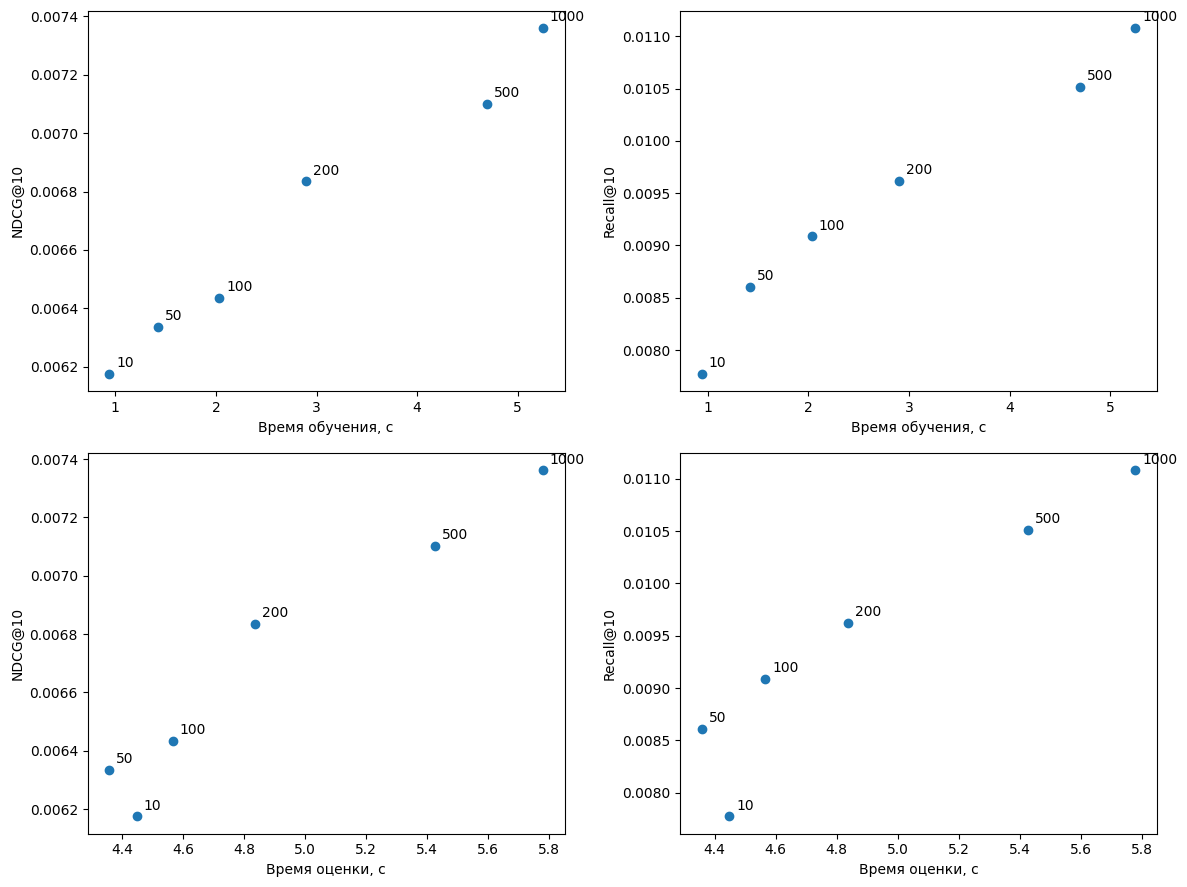

In [58]:
results = models[models["architecture"] == "I2I"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, time_col in enumerate(["fit_time", "eval_time"]):
    for j, metric in enumerate(["NDCG@10", "Recall@10"]):
        ax = axes[i, j]
        ax.scatter(results[time_col], results[metric])

        for _, row in results.iterrows():
            ax.annotate(int(row["n_neighbors"]), (row[time_col], row[metric]), xytext=(5, 5), textcoords="offset points")

        ax.set(xlabel="Время обучения, с" if i == 0 else "Время оценки, с", ylabel=metric)

plt.tight_layout()
plt.show()

Результаты на val не впечатляют. Интересно, что 10 и 50 почти одинаковые на NDCG и кратно различаются в Recall. Значит, модели не хватает n_neighbours более корректного подбора нижней части выдачи. Модель с 500 тяжелее, чем с 200, но не сильно улучшает метрики

### 4.2. ALS

В наших данных нету явной отрицательной обратной связи - только положительный сигнал (покупка), поэтому будем использовать Implicit ALS

Представляем пользователей и товары в виде векторов, скалярное произведение которых отражает предпочтения пользователя. Обучаем векторы поочердно, минимизируя взвешенную квадратичную ошибку: уверенность в положительных взаимодействиях зависит от количества покупок, а отсутствие покупки считается нулевым таргетом

$$
p_{ui} = \mathbf{1}[n_{ui}>0]
$$

$$
c_{ui} = 1 + \alpha n_{ui}
$$

$$
\min_{U,V} \sum_{u,i} c_{ui}(p_{ui}-U_u^\top V_i)^2 + \lambda\left(\sum_u\|U_u\|^2+\sum_i\|V_i\|^2\right)
$$

In [59]:
%%writefile models/als.py

import numpy as np
from scipy.linalg import solve
from tqdm.auto import tqdm


class ImplicitALS:
    def __init__(self, rank=32, alpha=10, regularization=0.1, iterations=5, seed=42):
        self.rank = rank
        self.alpha = alpha
        self.regularization = regularization
        self.iterations = iterations
        self.seed = seed

    def _update(self, X, fixed, targets=None):  # targets - чеховское ружье
        gram = fixed.T @ fixed
        eye = np.eye(self.rank, dtype=np.float32) * self.regularization
        updated = np.zeros((X.shape[0], self.rank), dtype=np.float32)

        for u in range(X.shape[0]):
            start, end = X.indptr[u:u + 2]
            if start == end:
                continue

            indices = X.indices[start:end]
            confidence = 1 + self.alpha * X.data[start:end]
            vectors = fixed[indices]

            A = gram + (vectors.T * (confidence - 1)) @ vectors + eye
            values = 1 if targets is None else targets.data[start:end]
            b = ((confidence * values)[:, None] * vectors).sum(axis=0)
            updated[u] = solve(A, b, assume_a="pos", check_finite=False)

        return updated

    def fit(self, X, popular_ids, verbose=False, targets=None):
        self.X = X
        self.popular_ids = np.asarray(popular_ids, dtype=np.int64)

        rng = np.random.default_rng(self.seed)
        self.user_embeds = rng.normal(0, 0.01, (X.shape[0], self.rank)).astype(np.float32)
        self.item_embeds = rng.normal(0, 0.01, (X.shape[1], self.rank)).astype(np.float32)

        X_T = X.T.tocsr()
        targets_T = targets.T.tocsr() if targets is not None else None
        
        for _ in tqdm(range(self.iterations), desc="ALS", disable=not verbose):
            self.user_embeds = self._update(X, self.item_embeds, targets)
            self.item_embeds = self._update(X_T, self.user_embeds, targets_T)

        return self

    def forward(self, user_ids, k=10):
        user_ids = np.asarray(user_ids, dtype=np.int64)
        result = np.tile(self.popular_ids[:k], (len(user_ids), 1))

        valid = (user_ids >= 0) & (user_ids < self.X.shape[0])
        warm = np.zeros(len(user_ids), dtype=bool)
        warm[valid] = self.X.indptr[user_ids[valid]] < self.X.indptr[user_ids[valid] + 1]

        if not warm.any():
            return result

        scores = self.user_embeds[user_ids[warm]] @ self.item_embeds.T
        indices = np.argpartition(scores, -k, axis=1)[:, -k:]
        order = np.argsort(-np.take_along_axis(scores, indices, axis=1), axis=1)

        result[warm] = np.take_along_axis(indices, order, axis=1)
        return result

Writing models/als.py


У нас 4 гиперпараметра. Сначала подберем первую пару, а потом - вторую. Исходя из высокой разреженности матрицы, выберем значения рангов небольшими. Остальные значения - просто общепринятые варианты, которые предложил чатгпт

In [60]:
from models.als import ImplicitALS
from sklearn.model_selection import ParameterGrid


def train_als_grid(grid, models):
    for params in ParameterGrid(grid):
        als = ImplicitALS(**params, seed=SEED)

        start = time.perf_counter()
        als.fit(C, popular_ids, verbose=True)
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        metrics = evaluate(als, val_targets_ids, verbose=True)
        eval_time = time.perf_counter() - start

        models.loc[len(models), ["architecture", *params, "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
            "ALS", *params.values(), metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
        ]

In [61]:
C = interaction_matrix(train, n_users, n_items, binary=False)

als_grid = {
    "rank": [16, 32, 64],
    "alpha": [5, 20],
    "regularization": [0.1],
    "iterations": [5],
}

train_als_grid(als_grid, models)

ALS:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/5 [00:00<?, ?it/s]

...

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

Время замера метрик не различается, поэтому не будем его отображать

In [62]:
def plot_models(results, label_fn):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
        ax.scatter(results["fit_time"], results[metric])

        for _, row in results.iterrows():
            ax.annotate(label_fn(row), (row["fit_time"], row[metric]), xytext=(5, 5), textcoords="offset points")

        ax.set(xlabel="Время обучения, с", ylabel=metric)

    plt.tight_layout()
    plt.show()

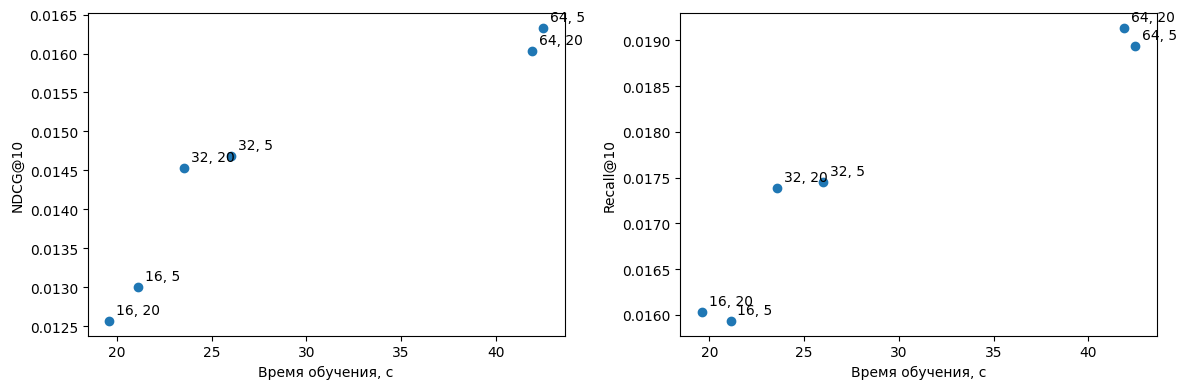

In [63]:
results = models[models["architecture"] == "ALS"]
plot_models(results, lambda row: f'{int(row["rank"])}, {int(row["alpha"])}')

Параметр alpha существенно не влияет на качество, а вот больший ранг дает улучшение метрики

In [64]:
als_grid = {
    "rank": [64],
    "alpha": [5],
    "regularization": [0.1, 0.5],
    "iterations": [3, 7],
}

train_als_grid(als_grid, models)

ALS:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/7 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/7 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

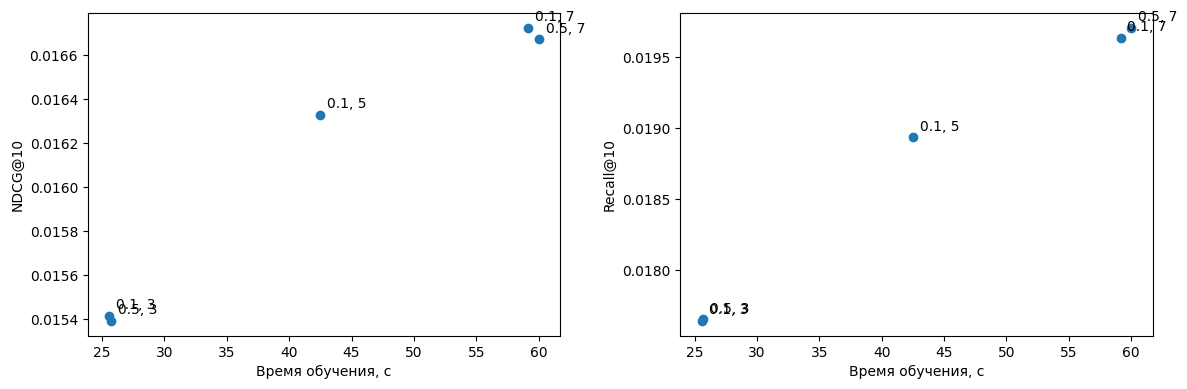

In [65]:
results = models[(models["architecture"] == "ALS") & (models["alpha"] == 5) & (models["rank"] == 64)]
plot_models(results, lambda row: f'{row["regularization"]}, {int(row["iterations"])}')

Регуляризация повлияла несущественно, а количество итераций немного улучшило показатели

In [66]:
als_grid = {
    "rank": [64, 128],
    "alpha": [5],
    "regularization": [0.5],
    "iterations": [9, 11],
}

train_als_grid(als_grid, models)

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/11 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/11 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

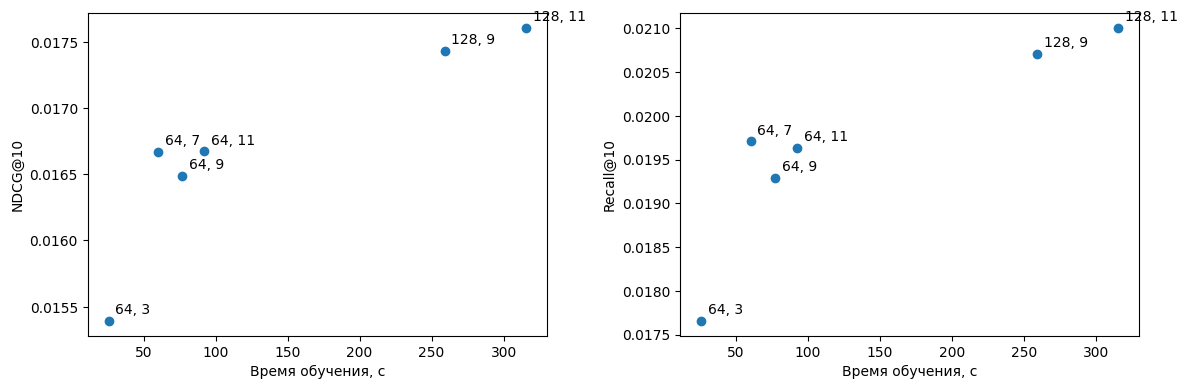

In [67]:
results = models[(models["architecture"] == "ALS") & (models["alpha"] == 5) & (models["regularization"] == 0.5)]
plot_models(results, lambda row: f'{int(row["rank"])}, {int(row["iterations"])}')

Размерность эмбеддингов влияет сильнее, чем количество итераций (на моих данных и значениях зафиксированных гиперпараметров). Сделаем выбор второго упомянутого гиперпараметра в пользу простоты модели

### 4.3. SLIM

Для использования EASE пришлось бы обращать огромную матрицу. Мои ресурсы ограничены бесплатной подпиской Kaggle, поэтому остановлюсь на SLIM. На лекции было предложено проводить спуск покоординатно, поэтому пока что все еще останемся жить на numpy

Обучаем разреженную матрицу весов, которая позволяет предсказывать покупки одних товаров по покупкам других. Для каждого товара выбираем n_candidates похожих товаров и обучаем их неотрицательные веса покоординатным спуском с L1- и L2-регуляризацией

$$
\min_W \frac{1}{2}\|X-XW\|_F^2 + \lambda_1\sum_{i,j}|W_{ij}| + \frac{\lambda_2}{2}\|W\|_F^2,
$$

$$
W_{ij}\geq 0
$$
$$
W_{ii}=0
$$

$$
\hat R = XW
$$

In [68]:
%%writefile models/slim.py

import numpy as np
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm


class SLIM:
    def __init__(self, n_candidates, l1, l2, iterations, precision):
        self.n_candidates = n_candidates
        self.l1 = l1
        self.l2 = l2
        self.iterations = iterations
        self.precision = precision

    def fit(self, X, popular_ids, verbose=False):
        self.X = X
        self.popular_ids = np.asarray(popular_ids, dtype=np.int64)

        X_csc = X.tocsc()
        gram = (X.T @ X).tocsc()
        gram.setdiag(0)
        gram.eliminate_zeros()

        n_users, n_items = X.shape
        counts = np.diff(X_csc.indptr)
        antinorm = np.zeros(n_items, dtype=np.float32)
        np.divide(1, np.sqrt(counts), out=antinorm, where=counts > 0)

        rows, cols, values = [], [], []

        for j in tqdm(range(n_items), desc="SLIM", disable=not verbose):
            start, end = gram.indptr[j:j + 2]
            neighbors = gram.indices[start:end]

            if len(neighbors) == 0:
                continue

            similarities = gram.data[start:end] * antinorm[neighbors] * antinorm[j]

            if len(neighbors) > self.n_candidates:
                top = np.argpartition(similarities, -self.n_candidates)[-self.n_candidates:]
                neighbors, similarities = neighbors[top], similarities[top]

            neighbors = neighbors[np.argsort(-similarities)]

            residual = np.zeros(n_users, dtype=np.float32)
            residual[X_csc.indices[X_csc.indptr[j]:X_csc.indptr[j + 1]]] = 1
            coefficients = np.zeros(len(neighbors), dtype=np.float32)

            for _ in range(self.iterations):
                max_change = 0

                for pos, i in enumerate(neighbors):
                    users = X_csc.indices[X_csc.indptr[i]:X_csc.indptr[i + 1]]
                    old = coefficients[pos]
                    new = max(0, (residual[users].sum() + counts[i] * old - self.l1) / (counts[i] + self.l2))
                    delta = new - old

                    if delta != 0:
                        residual[users] -= delta
                        coefficients[pos] = new
                        max_change = max(max_change, abs(delta))

                if max_change < self.precision:
                    break

            nonzero = coefficients > 0
            rows.extend(neighbors[nonzero].tolist())
            cols.extend([j] * int(nonzero.sum()))
            values.extend(coefficients[nonzero].tolist())

        self.W = csr_matrix((values, (rows, cols)), shape=(n_items, n_items), dtype=np.float32)
        return self

    def forward(self, user_ids, k=10):
        user_ids = np.asarray(user_ids, dtype=np.int64)
        result = np.tile(self.popular_ids[:k], (len(user_ids), 1))

        valid = (user_ids >= 0) & (user_ids < self.X.shape[0])
        warm = np.zeros(len(user_ids), dtype=bool)
        warm[valid] = self.X.indptr[user_ids[valid]] < self.X.indptr[user_ids[valid] + 1]

        if not warm.any():
            return result

        scores = (self.X[user_ids[warm]] @ self.W).tocsr()

        for row, pos in enumerate(np.flatnonzero(warm)):
            start, end = scores.indptr[row:row + 2]
            indices, values = scores.indices[start:end], scores.data[start:end]

            positive = values > 0
            indices, values = indices[positive], values[positive]

            if len(values) > k:
                top = np.argpartition(values, -k)[-k:]
                indices, values = indices[top], values[top]

            selected = indices[np.argsort(-values)].tolist()

            if len(selected) < k:
                selected_set = set(selected)
                for item in self.popular_ids:
                    if item not in selected_set:
                        selected.append(int(item))
                        selected_set.add(int(item))
                        if len(selected) == k:
                            break

            result[pos] = selected[:k]

        return result

Writing models/slim.py


Снова будем перебирать гиперпараметры группами. Параметр precision (иногда его называют toll) я перебирать не буду, так как его значение можно поставить как бы аналитически (по своему назначению похож на early stopping)

In [69]:
from models.slim import SLIM


def train_slim_grid(grid, models):
    for params in ParameterGrid(grid):
        slim = SLIM(**params)

        start = time.perf_counter()
        slim.fit(X, popular_ids, verbose=True)
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        metrics = evaluate(slim, val_targets_ids, verbose=True)
        eval_time = time.perf_counter() - start

        models.loc[len(models), ["architecture", *params, "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
            "SLIM", *params.values(), metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
        ]

In [70]:
slim_grid = {
    "n_candidates": [50, 100, 200],
    "l1": [1.0],
    "l2": [1.0],
    "iterations": [3, 5],
    "precision": [1e-4]
}

train_slim_grid(slim_grid, models)

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

...

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

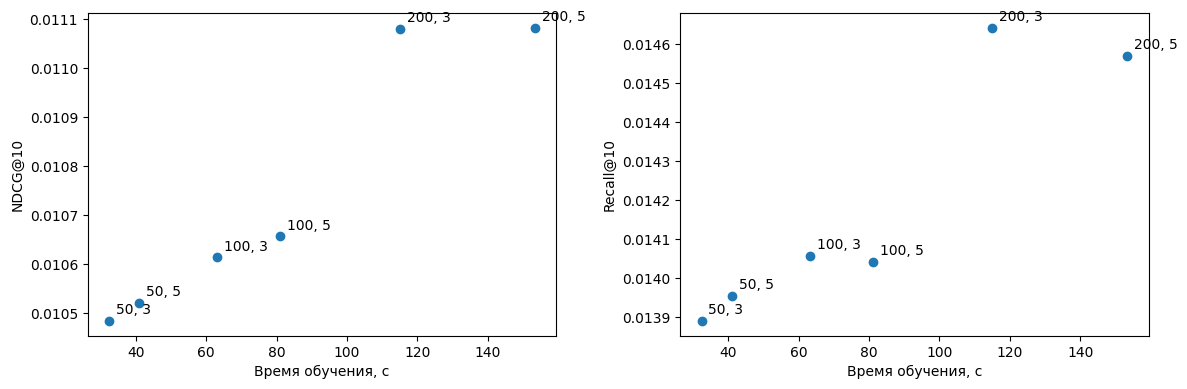

In [71]:
results = models[models["architecture"] == "SLIM"].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["n_candidates"])}, {int(row["iterations"])}')

Ситуация схожа с той, что мы наблюдали с предыдущей моделью. Тут возможно даже до 5 итерации доживают не все - обрезаются при малой delta (время различается не на 5/3=сикс-севен%). Причем интересно, что чем больше n_neighbours, тем меньше влияет iterations

In [72]:
slim_grid = {
    "n_candidates": [200],
    "l1": [0.1, 10],
    "l2": [0.1, 10],
    "iterations": [3],
    "precision": [1e-4]
}

train_slim_grid(slim_grid, models)

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

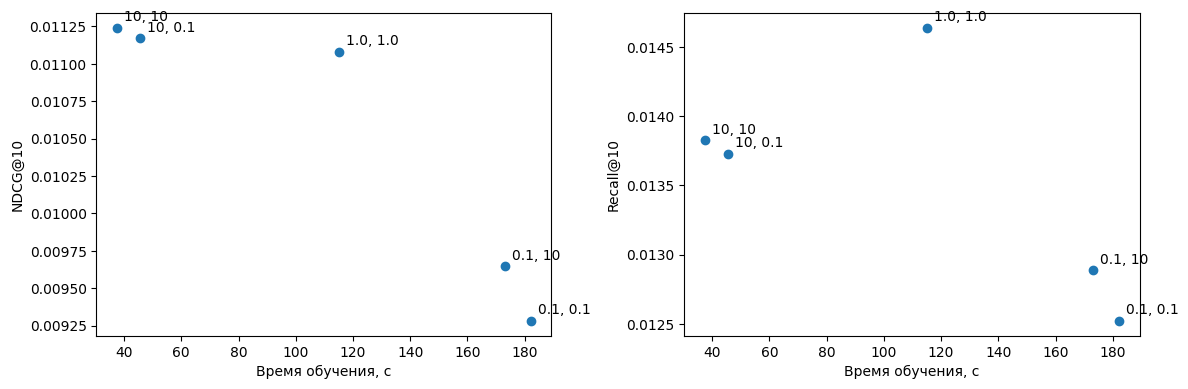

In [73]:
results = models[(models["architecture"] == "SLIM") & (models["n_candidates"] == 200) & (models["iterations"] == 3)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{row["l1"]}, {row["l2"]}')

Значение l2 регуляризации влияет незначительно, а вот l1 - серьезно. Матрица становится более разреженной и время обучение даже снижается. Тем не менее, по второстепенной метрике (Recall) замечено ухудшение при переходе от 1 к 10 (по NDCG прирост не такой заметный). Протестируем большее количество кандидатов прежде чем переходить к FM

In [74]:
slim_grid = {
    "n_candidates": [350, 500],
    "l1": [1.0],
    "l2": [1.0],
    "iterations": [3],
    "precision": [1e-4]
}

train_slim_grid(slim_grid, models)

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

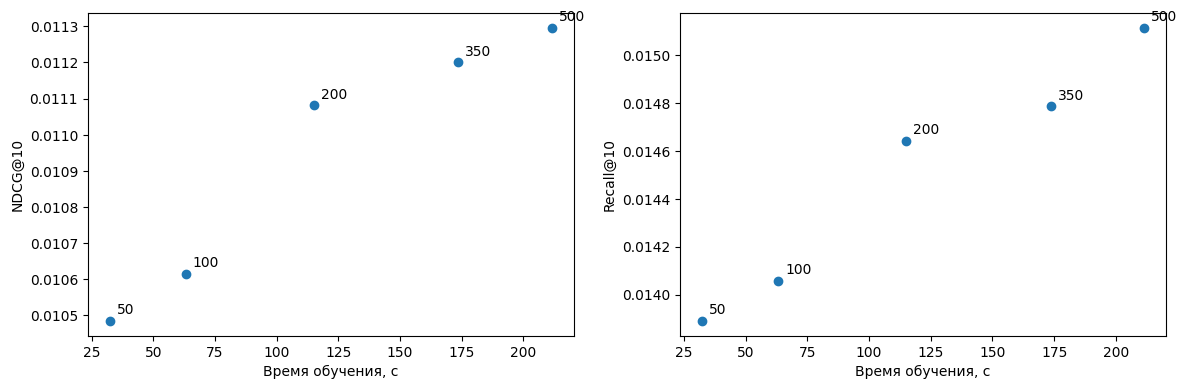

In [75]:
results = models[(models["architecture"] == "SLIM") & (models["l1"] == 1.0) & (models["l2"] == 1.0) & (models["iterations"] == 3)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["n_candidates"])}')

По основной метрике изменения в 4 знаке, что весьма мало

### 4.4. Factorization Machine

Используем не только историю взаимодействий, но и категориальные признаки пользователей и товаров. Модель обучает линейные веса и векторы признаков, через скалярные произведения которых учитывает попарные взаимодействия; обучается как бинарный классификатор

$$
\hat y(x) = w_0 + \sum_a w_a x_a + \sum_{a<b} ( v_a,v_b ) x_a x_b
$$

Считаем, что все признаки пользователя и товара указаны при создании аккаунта, то есть уже известны на момент просчета рекомендации

In [76]:
models_backup = models.copy()

Подобрались к одной из наиболее интересных (ну для меня по крайней мере) моделей. Здесь использовать GPU и PyTorch уже будет весьма и весьма эффективно, поэтому воспользуемся

In [77]:
import torch


user_columns = ["FN", "Active", "club_member_status", "fashion_news_frequency", "age_group"]
item_columns = ["product_type_name", "product_group_name", "colour_group_name", "price_category"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
optimizer = torch.optim.Adam
loss_fn = torch.nn.BCEWithLogitsLoss()

Из всех признаков числовым у нас остался толко age. Однако FM учтет возрастной признак (как любой числовой) в таком виде лишь линейно; категориальная версия более гибкая, поэтому предлагается возраст тоже категоризировать. В итоге все фичи категориальные

In [78]:
def add_age_group(customers, train, n_age_bins):
    customers = customers.copy()
    train_users = customers["user_id"].isin(train["user_id"].unique())
    _, bins = pd.qcut(customers.loc[train_users, "age"], q=n_age_bins, retbins=True, duplicates="drop")

    bins[0], bins[-1] = -np.inf, np.inf
    customers["age_group"] = pd.cut(customers["age"], bins=bins, labels=False)

    return customers

Фидбек у нас все еще только лишь позитивный, так что будем использовать negative sampling

In [79]:
%%writefile models/fm.py

import numpy as np
import pandas as pd
import torch
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm


class FM(torch.nn.Module):
    def __init__(self, hidden_size, lr, regularization, epochs, batch_size, seed, device, user_columns, item_columns, optimizer, loss_fn):
        super().__init__()
        self.hidden_size = hidden_size
        self.lr = lr
        self.regularization = regularization
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed
        self.device = torch.device(device)
        self.user_columns = user_columns
        self.item_columns = item_columns
        self.optimizer = optimizer
        self.loss_fn = loss_fn

    @staticmethod
    def _encode(data, id_col, columns, offset):
        data = data.sort_values(id_col)
        features = [np.arange(len(data), dtype=np.int64) + offset + 1]
        offset += len(data)

        for col in columns:
            codes, values = pd.factorize(data[col], sort=True)
            features.append(codes + offset + 1)
            offset += len(values)

        return torch.tensor(np.column_stack(features), dtype=torch.long), offset

    def _parts(self, x):
        v = self.embeddings(x)
        v_sum = v.sum(dim=1)
        score = self.linear(x).sum(dim=(1, 2)) + 0.5 * (v_sum.square().sum(dim=1) - v.square().sum(dim=(1, 2)))
        return score, v_sum

    def _score(self, users, items):
        u_score, u_vectors = self._parts(self.user_features[users])
        i_score, i_vectors = self._parts(self.item_features[items])
        return self.bias + u_score + i_score + (u_vectors * i_vectors).sum(dim=1)

    def _negative_sampling(self, users, seen, rng):
        items = rng.integers(self.n_items, size=len(users))
        bad = seen[users, items].A1 > 0

        while bad.any():
            items[bad] = rng.integers(self.n_items, size=bad.sum())
            bad = seen[users, items].A1 > 0

        return items

    def fit(self, train, customers, articles, popular_ids, history=None, verbose=False):
        rng = np.random.default_rng(self.seed)
        torch.manual_seed(self.seed)
        self.popular_ids = np.asarray(popular_ids, dtype=np.int64)
        self.n_users, self.n_items = len(customers), len(articles)

        users, offset = self._encode(customers, "user_id", self.user_columns, 0)
        items, offset = self._encode(articles, "item_id", self.item_columns, offset)

        positives = train[["user_id", "item_id"]].to_numpy(dtype=np.int64)
        users[~np.isin(np.arange(self.n_users), positives[:, 0]), 0] = 0

        self.user_features = torch.cat([users, torch.zeros((1, users.shape[1]), dtype=torch.long)]).to(self.device)
        self.item_features = items.to(self.device)

        self.bias = torch.nn.Parameter(torch.zeros(1))
        self.linear = torch.nn.Embedding(offset + 1, 1, padding_idx=0)
        self.embeddings = torch.nn.Embedding(offset + 1, self.hidden_size, padding_idx=0)

        torch.nn.init.zeros_(self.linear.weight)
        torch.nn.init.normal_(self.embeddings.weight, std=0.01)

        with torch.no_grad():
            self.embeddings.weight[0].zero_()

        self.to(self.device)
        optimizer = self.optimizer(self.parameters(), lr=self.lr, weight_decay=self.regularization)

        seen = csr_matrix((np.ones(len(positives)), (positives[:, 0], positives[:, 1])), shape=(self.n_users, self.n_items))

        progress = tqdm(range(self.epochs), desc="FM", disable=not verbose)

        for epoch in progress:
            self.train()
            order = rng.permutation(len(positives))
            total_loss = 0

            for start in range(0, len(order), self.batch_size):
                batch = positives[order[start:start + self.batch_size]]
                negative_items = self._negative_sampling(batch[:, 0], seen, rng)

                users = torch.tensor(np.tile(batch[:, 0], 2), device=self.device)
                items = torch.tensor(np.concatenate([batch[:, 1], negative_items]), device=self.device)
                targets = torch.tensor(np.r_[np.ones(len(batch)), np.zeros(len(batch))], dtype=torch.float32, device=self.device)

                loss = self.loss_fn(self._score(users, items), targets)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(targets)

            train_loss = total_loss / (2 * len(positives))

            if history is not None:
                history.append({"epoch": epoch + 1, "train_loss": train_loss})

            if verbose:
                progress.set_postfix(train_loss=round(train_loss, 4))

        return self

    @torch.no_grad()
    def forward(self, user_ids, k=10):
        user_ids = np.asarray(user_ids, dtype=np.int64)
        safe_users = np.where((user_ids >= 0) & (user_ids < self.n_users), user_ids, self.n_users)

        self.eval()
        item_score, item_vectors = self._parts(self.item_features)
        user_score, user_vectors = self._parts(self.user_features[torch.tensor(safe_users, device=self.device)])
        scores = user_vectors @ item_vectors.T + user_score[:, None] + item_score[None, :] + self.bias

        return scores.topk(k, dim=1).indices.cpu().numpy()

Writing models/fm.py


Посмотрим, сколько примерно требуется эпох по loss, зафиксировав остальные гиперпараметры и прогнав заведомо много эпох

In [80]:
from models.fm import FM


n_age_bins = 10
customers_fm = add_age_group(data_customers_processed, train, n_age_bins)

history = []

fm = FM(
    hidden_size=32,
    lr=1e-3,
    regularization=1e-5,
    epochs=200,
    batch_size=2048,
    seed=SEED,
    device=device,
    user_columns=user_columns,
    item_columns=item_columns,
    optimizer=optimizer,
    loss_fn=loss_fn
)

start = time.perf_counter()
fm.fit(train, customers_fm, data_articles_catalog_processed, popular_ids, history=history, verbose=True)
if device.type == "cuda":
    torch.cuda.synchronize()
fit_time = time.perf_counter() - start

start = time.perf_counter()
metrics = evaluate(fm, val_targets_ids, verbose=True)
if device.type == "cuda":
    torch.cuda.synchronize()
eval_time = time.perf_counter() - start

models.loc[len(models), ["architecture", "hidden_size", "lr", "regularization", "epochs", "batch_size", "n_age_bins", "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
    "FM", fm.hidden_size, fm.lr, fm.regularization, fm.epochs, fm.batch_size, n_age_bins, metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
]

FM:   0%|          | 0/200 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

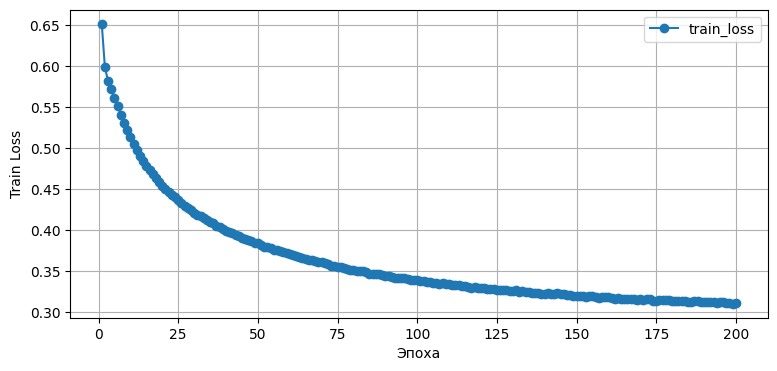

In [81]:
pd.DataFrame(history).plot(x="epoch", y="train_loss", marker="o", figsize=(9, 4), grid=True)
plt.xlabel("Эпоха")
plt.ylabel("Train Loss")
plt.show()

In [82]:
def train_fm_grid(grid, models):
    for params in ParameterGrid(grid):
        n_age_bins = params["n_age_bins"]
        fm_params = {k: v for k, v in params.items() if k != "n_age_bins"}
        customers_fm = add_age_group(data_customers_processed, train, n_age_bins)

        fm = FM(**fm_params, batch_size=2048, seed=SEED, device=device, user_columns=user_columns, item_columns=item_columns, optimizer=optimizer, loss_fn=loss_fn)

        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        fm.fit(train, customers_fm, data_articles_catalog_processed, popular_ids, verbose=True)
        if device.type == "cuda":
            torch.cuda.synchronize()
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        metrics = evaluate(fm, val_targets_ids, verbose=True)
        if device.type == "cuda":
            torch.cuda.synchronize()
        eval_time = time.perf_counter() - start

        models.loc[len(models), ["architecture", *params, "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
            "FM", *params.values(), metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
        ]

In [83]:
fm_grid = {
    "hidden_size": [16, 32, 64],
    "lr": [1e-3, 2e-4],
    "regularization": [1e-5],
    "epochs": [75],
    "n_age_bins": [10],
}

train_fm_grid(fm_grid, models)

FM:   0%|          | 0/75 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/75 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/75 [00:00<?, ?it/s]

...

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/75 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/75 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

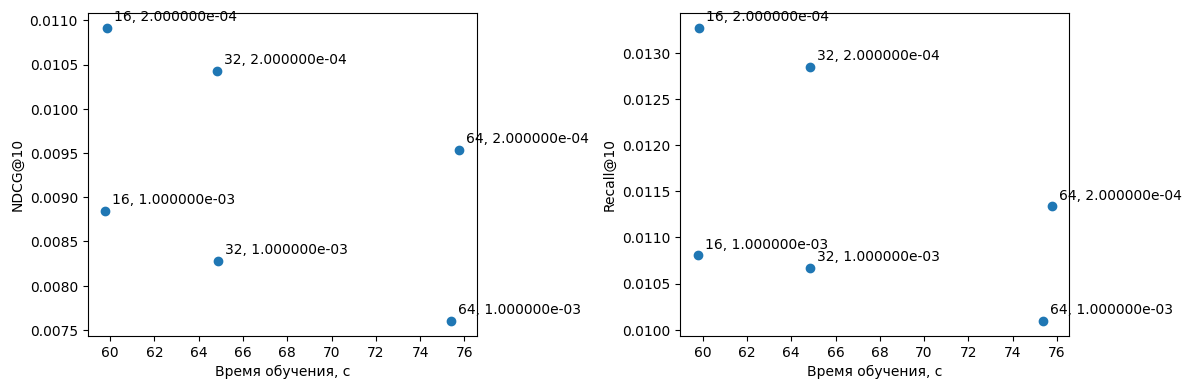

In [84]:
results = models[(models["architecture"] == "FM") & (models["epochs"] == 75)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["hidden_size"])}, {row["lr"]:e}')

По графику меньшее значение lr показывает себя лучше, но усложнение модели по размеру векторов ведет к ухудшению метрик. Переобучение? Проверим

In [85]:
fm_grid = {
    "hidden_size": [32],
    "lr": [2e-4],
    "regularization": [1e-5],
    "epochs": [25, 50],
    "n_age_bins": [10],
}

train_fm_grid(fm_grid, models)

FM:   0%|          | 0/25 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

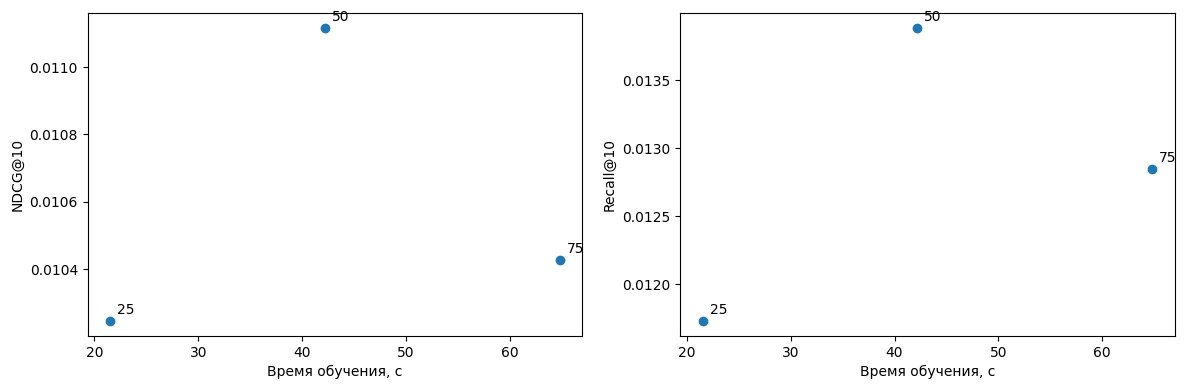

In [86]:
results = models[(models["architecture"] == "FM") & (models["lr"] == 2e-4) & (models["hidden_size"] == 32)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["epochs"])}')

Возможно, действительно было переобучение

In [87]:
fm_grid = {
    "hidden_size": [16, 64],
    "lr": [2e-4],
    "regularization": [1e-5],
    "epochs": [50],
    "n_age_bins": [10],
}

train_fm_grid(fm_grid, models)

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

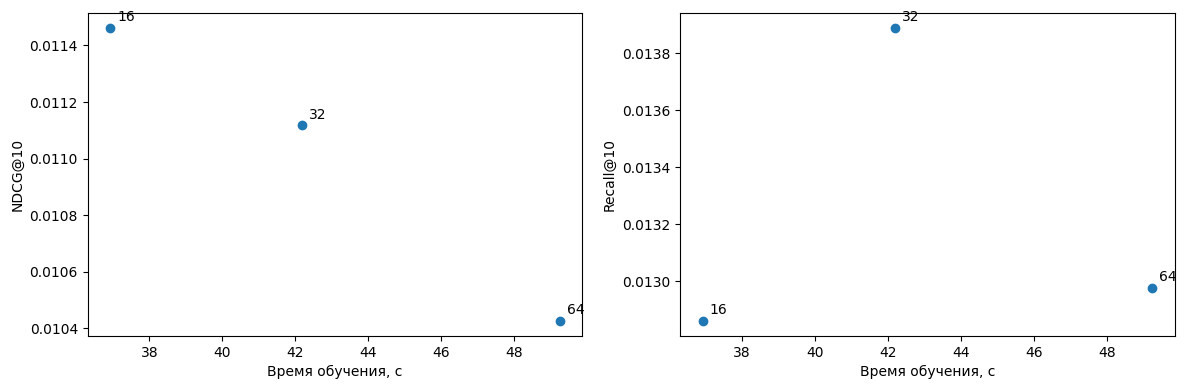

In [88]:
results = models[(models["architecture"] == "FM") & (models["lr"] == 2e-4) & (models["epochs"] == 50)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["hidden_size"])}')

По основной метрике хочется сделать выбор в сторону более простой модели

In [89]:
fm_grid = {
    "hidden_size": [16],
    "lr": [2e-4],
    "regularization": [1e-4],
    "epochs": [50],
    "n_age_bins": [7, 13],
}

train_fm_grid(fm_grid, models)

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

In [96]:
fm_grid = {
    "hidden_size": [16],
    "lr": [2e-4],
    "regularization": [1e-4],
    "epochs": [50],
    "n_age_bins": [10],
}

train_fm_grid(fm_grid, models)

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

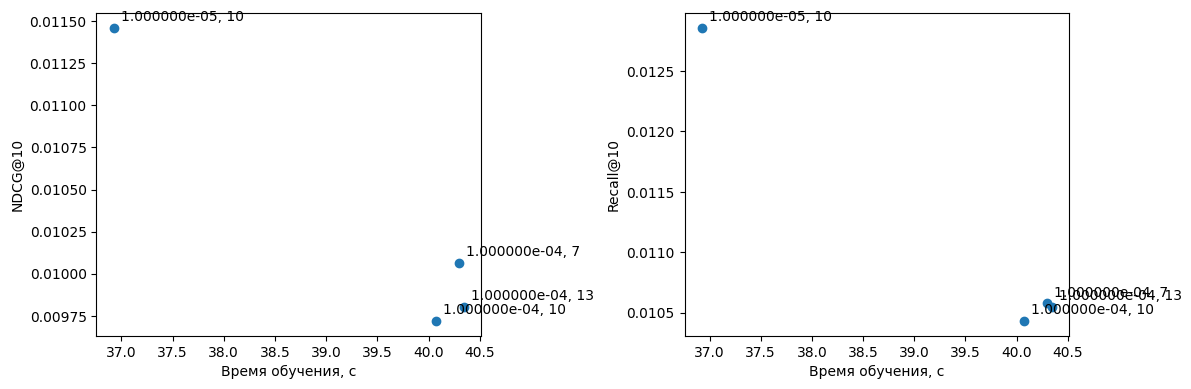

In [97]:
results = models[(models["architecture"] == "FM") & (models["lr"] == 2e-4) & (models["hidden_size"] == 16) & (models["epochs"] == 50)].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{row["regularization"]:e}, {int(row["n_age_bins"])}')

Разница по количеству бинов пренебрежимая (оставляем среднее значение), а вот регуляризация меньшая показала себя лучше большей

### 4.5. ALS с кастомным таргетом

timeSVD++ имеет хороший потенциал для данных с небинарными оценками, но в нашем датасете только факт покупки, поэтому я решил выбрать ImplicitALS с кастомным таргетом для этого пункта

Естественно, будем учитывать время. Часто в распределениях по времени встречается экспонента, поэтому хочется ее задействовать. А еще было бы удобно оставить таргет в диапазоне [0, 1]. Поэтому, беру такой таргет:

$$
p_{ui} = 1 - exp(-\Sigma_{t_j} exp(-\frac{t_0 - t_j}{\tau}))
$$

Тут $t_0$ - последняя дата обучения, а $\tau$ - гиперпараметр 

In [91]:
%%writefile models/temporal_als.py

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from models.als import ImplicitALS


class TemporalALS(ImplicitALS):
    def __init__(self, tau, **kwargs):
        super().__init__(**kwargs)
        self.tau = tau

    def fit(self, X, train, popular_ids, cutoff, verbose=False):
        days = (pd.Timestamp(cutoff) - train["t_dat"]).dt.days.to_numpy()
        weights = np.exp(-days / self.tau).astype(np.float32)
        recency = csr_matrix((weights, (train["user_id"], train["item_id"])), shape=X.shape)

        targets = X.copy()
        targets.data = -np.expm1(-recency.data)

        return super().fit(X, popular_ids, verbose=verbose, targets=targets)

Writing models/temporal_als.py


Вот так вот минималистично получилось

In [92]:
from models.temporal_als import TemporalALS


def train_temporal_als_grid(grid, models):
    for params in ParameterGrid(grid):
        als = TemporalALS(**params, seed=SEED)

        start = time.perf_counter()
        als.fit(C, train, popular_ids, cutoff="2019-11-01", verbose=True)
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        metrics = evaluate(als, val_targets_ids, verbose=True)
        eval_time = time.perf_counter() - start

        models.loc[len(models), ["architecture", *params, "NDCG@10", "Recall@10", "fit_time", "eval_time"]] = [
            "TemporalALS", *params.values(), metrics["NDCG@10"], metrics["Recall@10"], fit_time, eval_time
        ]

Гиперпараметры (кроме тау) у нас уже подобраны в обычном ALS (вообще могут быть минорные отличия в поведении в сравнении с обычной версией ALS, но пренебрежем ими), поэтому остется только тау подобрать

In [93]:
temporal_grid = {
    "rank": [128],
    "alpha": [5],
    "regularization": [0.5],
    "iterations": [9],
    "tau": [30, 90, 180],
}

train_temporal_als_grid(temporal_grid, models)

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/31 [00:00<?, ?it/s]

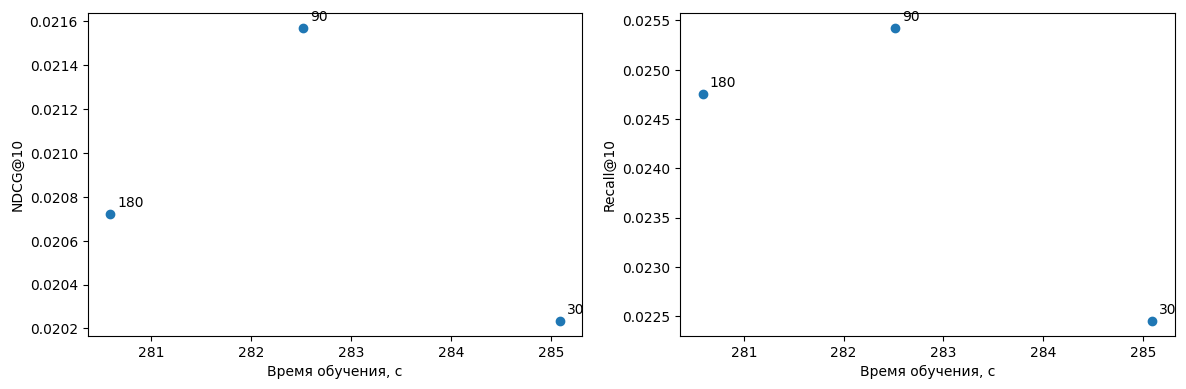

In [94]:
results = models[models["architecture"] == "TemporalALS"].sort_values("NDCG@10", ascending=False)
plot_models(results, lambda row: f'{int(row["tau"])}')

Лучше всего себя показал tau равный трем месяцем. Вилимо, при 180 затухание слишком большое, а при 30 слишком мало новой информации-разницы от времени в таргете. Будем использовать его в сравнении с обычным ImplicitALS

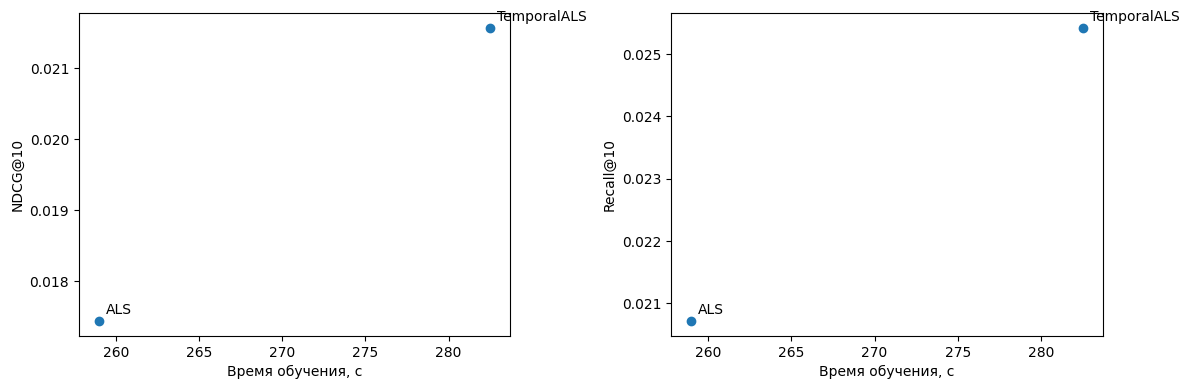

In [95]:
best_als = models[(models["architecture"] == "ALS") & (models["rank"] == 128) & (models["alpha"] == 5) & (models["regularization"] == 0.5) & (models["iterations"] == 9)].sort_values("NDCG@10", ascending=False).head(1)
temporal = models[(models["architecture"] == "TemporalALS") & (models["rank"] == 128) & (models["alpha"] == 5) & (models["regularization"] == 0.5) & (models["iterations"] == 9) & (models["tau"] == 90)]

comparison = pd.concat([best_als, temporal])

plot_models(comparison, lambda row: "ALS" if row["architecture"] == "ALS" else 'TemporalALS')

Время обучение увеличилось, но зато имеется очень существенный прирост по обоим метрикам

## 5. Сравнение на test

Протокол проверки уже выбран и выборки подготовлены в 3 разделе, поэтому  можно сразу приступать к дообучению на train+val лучших (или наиболее простых из лучших при паритете) моделей каждого типа. Гиперпараметры зафиксированы по val, здесь val лишь для дополнения обучающей выборки

In [98]:
best_params = {
    "I2I": {"n_neighbors": 200},
    "ALS": {"rank": 128, "alpha": 5, "regularization": 0.5, "iterations": 9},
    "SLIM": {"n_candidates": 200, "l1": 1.0, "l2": 1.0, "iterations": 3, "precision": 1e-4},
    "FM": {"hidden_size": 16, "lr": 2e-4, "regularization": 1e-5, "epochs": 50, "batch_size": 2048, "n_age_bins": 10},
    "TemporalALS": {"rank": 128, "alpha": 5, "regularization": 0.5, "iterations": 9, "tau": 90},
}

X_new = interaction_matrix(train_new, n_users_new, n_items_new)
C_new = interaction_matrix(train_new, n_users_new, n_items_new, binary=False)
customers_fm_new = add_age_group(data_customers_processed_new, train_new, best_params["FM"]["n_age_bins"])

runs_new = []

def test_model(name, model, *args, **kwargs):
    start = time.perf_counter()
    model.fit(*args, **kwargs)
    if isinstance(model, FM) and model.device.type == "cuda":
        torch.cuda.synchronize()
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    metrics = evaluate(model, test_targets_ids, verbose=True)
    if isinstance(model, FM) and model.device.type == "cuda":
        torch.cuda.synchronize()
    eval_time = time.perf_counter() - start

    runs_new.append({"architecture": name, **best_params[name], "NDCG@10": metrics["NDCG@10"], "Recall@10": metrics["Recall@10"], "fit_time": fit_time, "eval_time": eval_time})


test_model("I2I", I2I(**best_params["I2I"]), X_new, popular_ids_new)

test_model("ALS", ImplicitALS(**best_params["ALS"], seed=SEED), C_new, popular_ids_new, verbose=True)

test_model("SLIM", SLIM(**best_params["SLIM"]), X_new, popular_ids_new, verbose=True)

fm_params = {k: v for k, v in best_params["FM"].items() if k != "n_age_bins"}
fm = FM(**fm_params, seed=SEED, device=device, user_columns=user_columns, item_columns=item_columns, optimizer=optimizer, loss_fn=loss_fn)
test_model("FM", fm, train_new, customers_fm_new, data_articles_catalog_processed_new, popular_ids_new, verbose=True)

test_model("TemporalALS", TemporalALS(**best_params["TemporalALS"], seed=SEED), C_new, train_new, popular_ids_new, cutoff="2019-12-01", verbose=True)

models_new = pd.DataFrame(runs_new)

Evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

SLIM:   0%|          | 0/20000 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

FM:   0%|          | 0/50 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

ALS:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/30 [00:00<?, ?it/s]

Посмотрим на результат сначала в таблице

In [99]:
models_new["params"] = models_new["architecture"].map(best_params)
models_new[["architecture", "params", "NDCG@10", "Recall@10", "fit_time", "eval_time"]].sort_values("NDCG@10", ascending=False)

,architecture,params,NDCG@10,Recall@10,fit_time,eval_time
4,TemporalALS,"{'rank': 128, 'alpha': 5, 'regularization': 0....",0.022191,0.028139,295.637950,5.990958
1,ALS,"{'rank': 128, 'alpha': 5, 'regularization': 0....",0.017470,0.021599,263.777828,5.956526
2,SLIM,"{'n_candidates': 200, 'l1': 1.0, 'l2': 1.0, 'i...",0.010753,0.015759,123.113449,4.050802
3,FM,"{'hidden_size': 16, 'lr': 0.0002, 'regularizat...",0.009073,0.011537,43.706378,4.087040
0,I2I,{'n_neighbors': 200},0.008221,0.012074,3.070816,4.323529


И на графике по времени обучения (время инференса отличается несущественно)

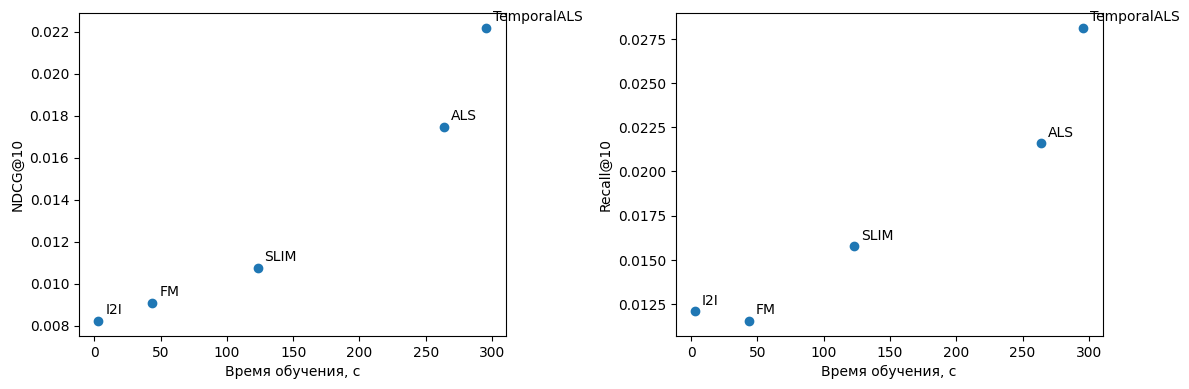

In [100]:
plot_models(models_new, lambda row: row["architecture"])

Но глобально не так важно время обучения, сколько сами метрики. Нарисуем на одном графике

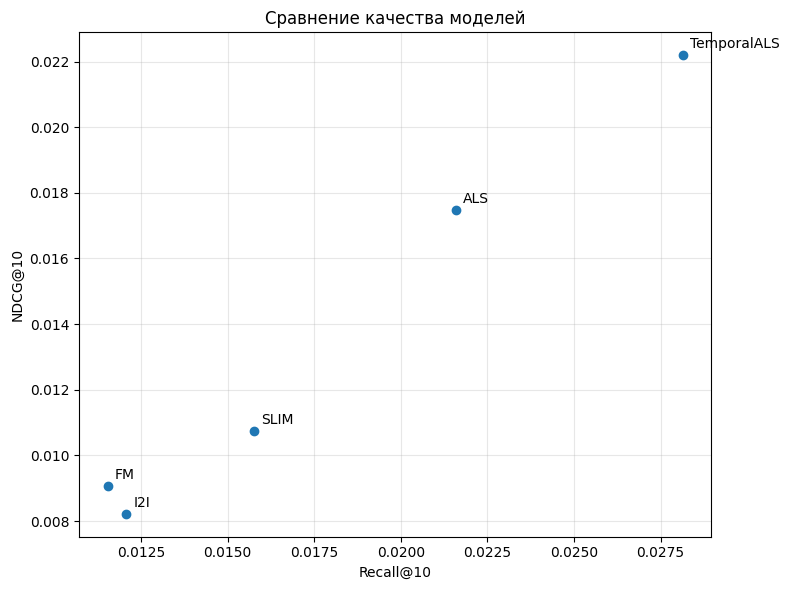

In [101]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(models_new["Recall@10"], models_new["NDCG@10"])

for _, row in models_new.iterrows():
    ax.annotate(row["architecture"], (row["Recall@10"], row["NDCG@10"]), xytext=(5, 5), textcoords="offset points")

ax.set(xlabel="Recall@10", ylabel="NDCG@10", title="Сравнение качества моделей")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Лучше всех показал себя TemporalALS

## 6. Выводы

У меня изначально было желание поработать с ранжированием в ecom, поэтому подобрать достойный датасет было отдельной задачей. К сожалению, в этой сфере (возможно, связано с чувствительностью данных) не так много больших (не синтетических!) датасетов с удобными именно под нашу задачу (рекомендации) данных. Либо мало данных (как в GB RecSys June-July 2022), либо мало признаков объектов (как в eCommerce), либо датасет совсем под другую задачу (например, от X5 датасет для аплифта). Компромисс выбранного датасета заключается в таргете - только покупки, без отрицательных или нейтральных исходов. Это несколько повлияло на выбор модели (в TemporalALS). Еще обращать данные достаточно разреженные, а для EASE нужно было обращаться матрицу |catalog| x |catalog| - пришлось бы делать каталог для рекомендаций совмем маленьким. Справедливости ради, во время EDA было выяснено, что качество датасета неплохое

Сам датасет достаточно большой и на бесплатном кагле работать бы у меня не получилось, поэтому мы ограничились одним годов, посэмплировали случайных пользователей и рекомендовали товары из отобранного каталога популярных товаров. В прочем, использование каталога решается добавлением exploration, но это продуктовое решение

Пришлось придумать подход к использованию цены в качестве признака. Использовать напрямую как признак нельзя, так как при каждом взаимодействии цена различается. В итоге категоризовали. Было бы возможно интересно проверить, как ее можно вставить в кастомный таргет ALS, но это за гранью текущей работы

Большинство моделей было удобнее запускать на numpy ввиду использования разреженных представлений матриц. Тем не менее, время обучение моделей обычно было порядка нескольких минут, так что весьма терпимо (обучили несколько десятков моделей, так что большее время обучения было бы неприемлемым)

При сравнении моделей не всегда оказывалось, что сложные модели побеждали простые (например, оба ImplicitALS победили FM). Даже на таких масштабах при сравнении на валидации наблюдалось переобучение

Выбор метрик считаю хорошим, так как NDCG это один из общепринятых стандартов, а Recall давал при сравнении некоторые инсайды (в определенных случаях результат по Recall отличался от того по NDCG). Порядки результатов неутешительные - меньше нескольких процентов обычно. Однако это нормальная практика для такой задачи. В соревновании датасета есть лидерборд по Precision@12 и там числа подобного порядка то же, так что и у нас все не плохо вышло

Если говорить о итоговых метриках моделей, победа однозначно за ALS с таргетом со временем. Но даже обычный ALS показал себя лучше отстальных. Качество FM на уровне обычного I2I; считаю, что его потенциал точно не раскрыт (скорее всего требуется более тщательный feature engineering, но опять же это за гранью дз). Предположу, что более продвинутая обработка холодных объектов потенциально может значительно улучшить показатели

In [103]:
# from importlib.metadata import version, PackageNotFoundError


# packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "torch", "tqdm", "kaggle", "ipykernel"]

# with open("requirements.txt", "w") as f:
#     for package in packages:
#         try:
#             f.write(f"{package}=={version(package)}\n")
#         except PackageNotFoundError:
#             f.write(f"{package}\n")